In [58]:
# Zipf's Law: SETIMES Bulgarian-Turkish parallel newspaper text (bg-tr) (corpus 3)

In [59]:
from collections import Counter
import matplotlib.pyplot as plt

In [60]:
# Loading the dataset
from datasets import load_dataset
dataset = load_dataset("community-datasets/setimes", "bg-tr")

In [61]:
# Loop through the dataset and collect Bulgarian and Turkish sentences separately
bulgarian_texts = []
turkish_texts = []

for row in dataset["train"]:
    bulgarian_texts.append(row["translation"]["bg"])
    turkish_texts.append(row["translation"]["tr"])

print(len(bulgarian_texts))
print(len(turkish_texts))

206071
206071


The Bulgarian and Turkish sections of the SETIMES corpus were treated as two separate corpora. 

In [62]:
# BULGARIAN word counting
from collections import Counter
import string

punctuation = string.punctuation

def word_frequencies_bg(texts):

    counter = Counter()

    for sentence in texts:
        sentence = sentence.lower()

        for p in punctuation:
            sentence = sentence.replace(p, " ")

        counter.update(sentence.split())

    return counter

The section of the corpus in Bulgarian was converted to lowercase to avoid counting orthographic variants such as uppercase and lowercase forms as distinct words. Punctuation marks were removed and tokenization was performed by splitting the text at whitespace.

In [63]:
# TURKISH word counting 1: remove punctuation; apostrophes preserved for their orthographic and morphological relevance in Turkish
punctuation_with_apo = string.punctuation.replace("'", "")

def word_frequencies_tr_keep(texts):

    counter = Counter()

    for sentence in texts:
        sentence = sentence.lower()

        for p in punctuation_with_apo:
            sentence = sentence.replace(p, " ")

        counter.update(sentence.split())

    return counter

Two different treatments of apostrophes in Turkish:
1. Apostrophes preserved

In [64]:
# TURKISH word counting 2: remove punctuation; apostrophes treated as token boundaries, separating proper names and other stems from attached suffixes

def word_frequencies_tr_split(texts):

    counter = Counter()

    for sentence in texts:
        sentence = sentence.lower()

        for p in string.punctuation:
            sentence = sentence.replace(p, " ")

        counter.update(sentence.split())

    return counter

2. Apostrophes treated as token boundaries

In [65]:
# Corpus in the def functions
bg_freq = word_frequencies_bg(bulgarian_texts)

tr_freq_keep = word_frequencies_tr_keep(turkish_texts)
tr_freq_split = word_frequencies_tr_split(turkish_texts)

In [66]:
# Words by descending frequency. Zipf's law requires words sorted from most frequent to least frequent
bg_sorted = bg_freq.most_common()
tr_sorted_keep = tr_freq_keep.most_common()
tr_sorted_split = tr_freq_split.most_common()

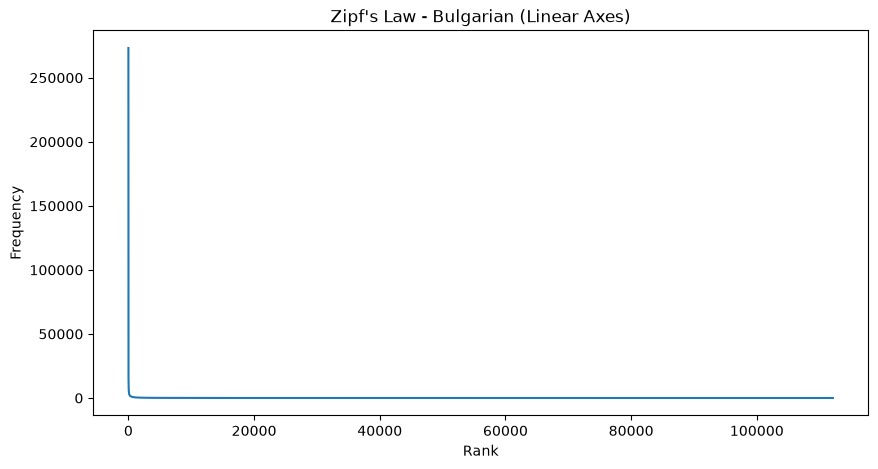

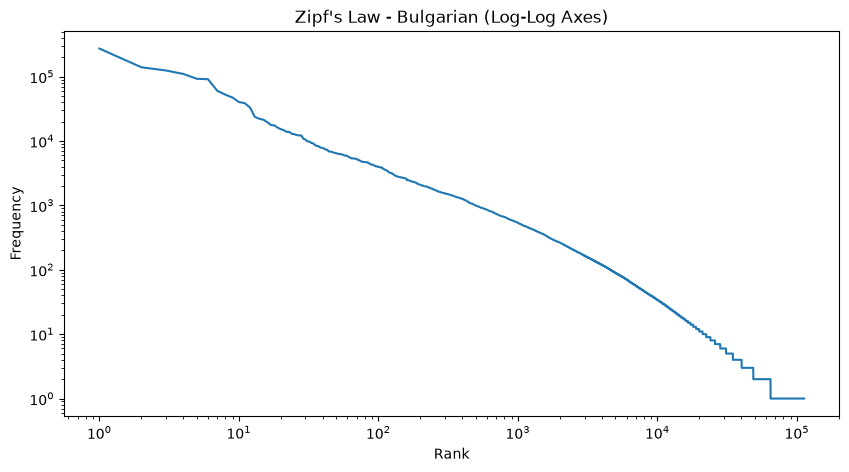

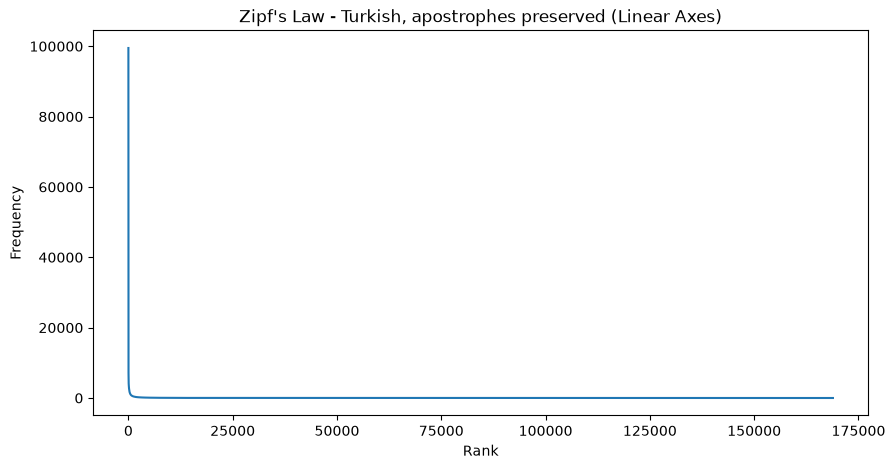

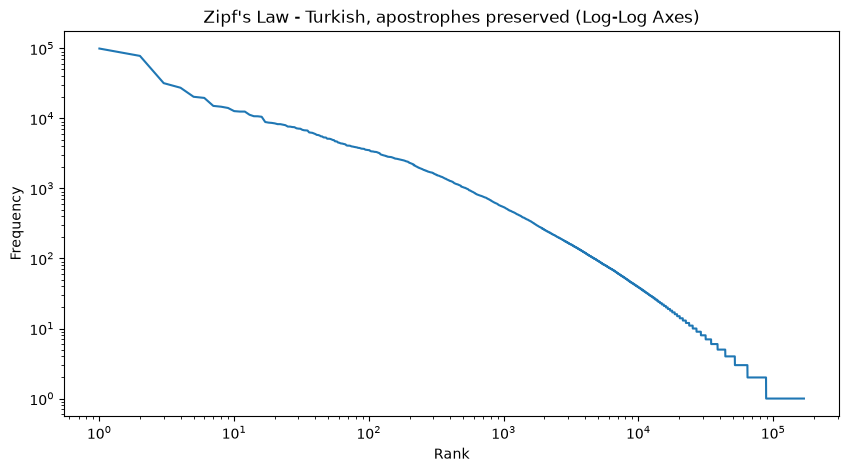

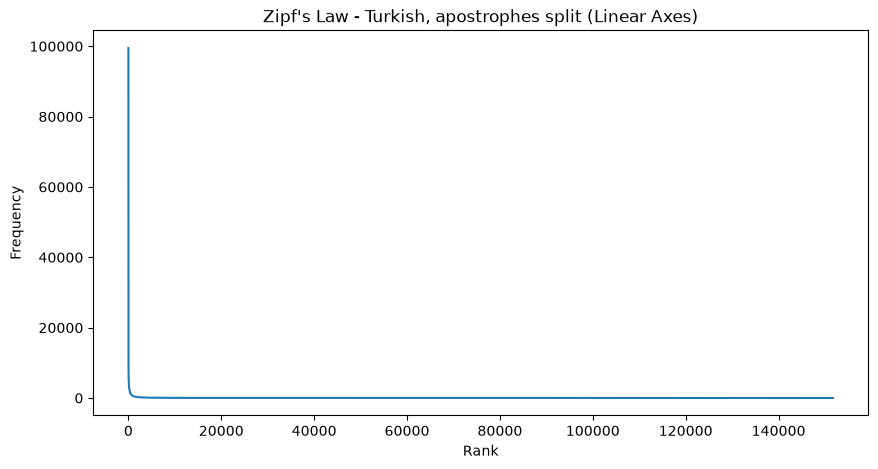

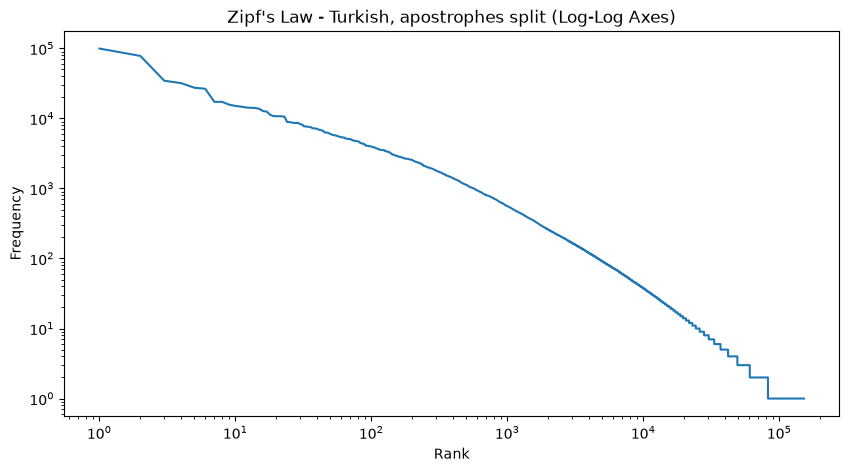

In [67]:
# Reusable function to create ranks for both languages and then plot all
def plot_zipf(sorted_words, language):

    # List comprehension - tuple unpacking - Create a list containing every frequency from the (word, frequency) pairs in sorted_words
    frequencies = [freq for word, freq in sorted_words]
    ranks = range(1, len(frequencies)+1)

    # linear
    plt.figure(figsize=(10,5))
    plt.plot(ranks, frequencies)
    plt.xlabel("Rank")
    plt.ylabel("Frequency")
    plt.title(f"Zipf's Law - {language} (Linear Axes)")
    plt.show()

    # log-log
    plt.figure(figsize=(10,5))
    plt.loglog(ranks, frequencies)
    plt.xlabel("Rank")
    plt.ylabel("Frequency")
    plt.title(f"Zipf's Law - {language} (Log-Log Axes)")
    plt.show()


plot_zipf(bg_sorted, "Bulgarian")
plot_zipf(tr_sorted_keep, "Turkish, apostrophes preserved")
plot_zipf(tr_sorted_split, "Turkish, apostrophes split")

Linear and log-log plots were created for the rank-frequency distributions obtained (one for Bulgarian and two for Turkish).

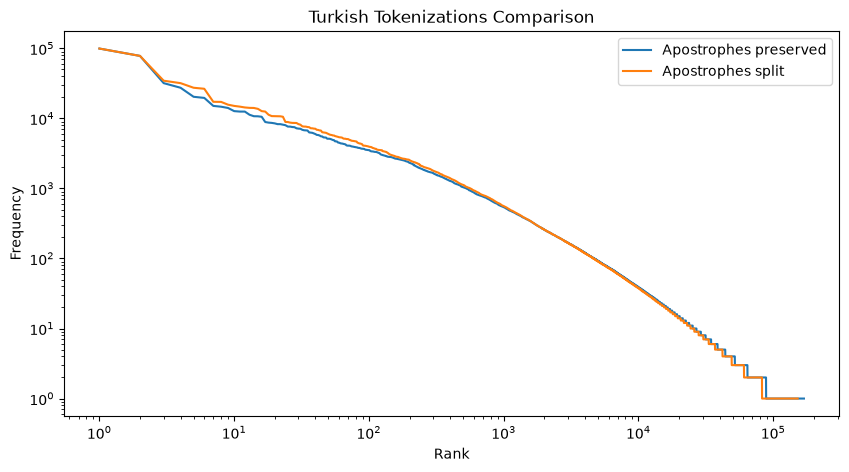

In [68]:
# Creating a specific log-log plot to compare the results of the different analysis on the Turkish language
freq_keep = [freq for word, freq in tr_sorted_keep]
freq_split = [freq for word, freq in tr_sorted_split]

rank_keep = range(1, len(freq_keep)+1)
rank_split = range(1, len(freq_split)+1)

# log-log
plt.figure(figsize=(10,5))

plt.loglog(rank_keep, freq_keep, label="Apostrophes preserved")
plt.loglog(rank_split, freq_split, label="Apostrophes split")
plt.xlabel("Rank")
plt.ylabel("Frequency")
plt.title("Turkish Tokenizations Comparison")

plt.legend()
plt.show()

Comparison of the two Turkish tokenization strategies using a log-log plot.

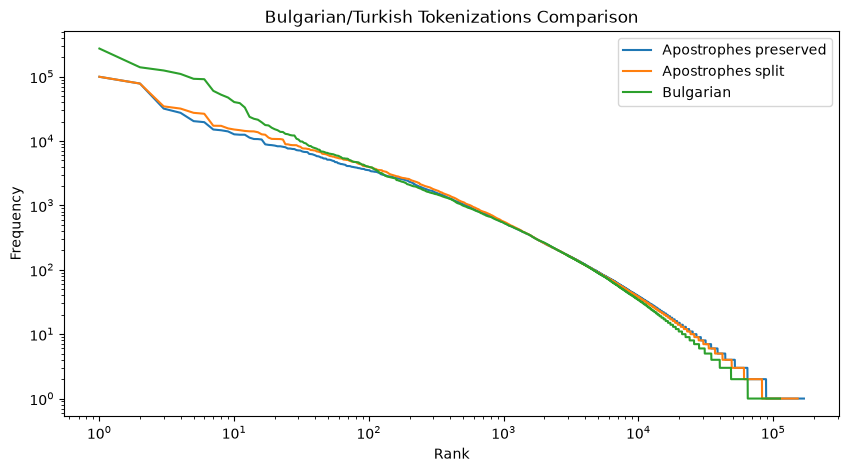

In [69]:
# Creating a log-log plot comparing the Bulgarian corpus with the two Turkish tokenization strategiesplt.figure(figsize=(10,5))
plt.figure(figsize=(10,5))

plt.loglog(rank_keep, freq_keep, label="Apostrophes preserved")
plt.loglog(rank_split, freq_split, label="Apostrophes split")

freq_bg = [freq for word, freq in bg_sorted]
rank_bg = range(1, len(freq_bg)+1)
plt.loglog(rank_bg, freq_bg, label="Bulgarian")

plt.xlabel("Rank")
plt.ylabel("Frequency")
plt.title("Bulgarian/Turkish Tokenizations Comparison")

plt.legend()
plt.show()

Comparison of the Bulgarian corpus and the two Turkish tokenization strategies using a log-log plot.

All text was converted to lowercase to avoid counting orthographic variants such as uppercase and lowercase forms as distinct words. 
Punctuation marks were removed and tokenization was performed by splitting the text at whitespace.

For Turkish, an additional experiment was conducted concerning the treatment of apostrophes. 
Turkish is a highly agglutinative language, and in its orthography apostrophes are commonly used to separate proper nouns from grammatical suffixes.
Because these suffixes carry grammatical information, their treatment may influence the observed frequency distribution.

For this reason, two strategies were compared:
1. Apostrophes preserved: forms such as "parvulescu'ya" (meaning a movement "to Parvulescu") were treated as single tokens.
2. Apostrophes treated as token boundaries: apostrophes were removed during preprocessing, causing forms such as "parvulescu'nun" (meaning "of Parvulescu") 
to be split into separate tokens.

From a linguistic perspective, the second approach can be questioned, since the suffix tokens correspond to bound morphemes that are 
morphologically, phonologically and syntactically dependent on a lexical root. 
Nevertheless, it was interesting to investigate the extent to which this tokenization choice would affect the resulting Zipfian distribution.

Treating apostrophes differently changes the definition of what counts as a word and may therefore affects both vocabulary size and the observed frequency distribution. 
In particular, splitting forms at apostrophes can increase the frequency of grammatical elements that would otherwise remain attached to proper nouns.
The comparison between the two Turkish tokenization strategies revealed only minor differences in the log-log plot.

Finally, Bulgarian was compared with both Turkish distributions in a single log-log plot.
What stands out is mostly the difference between Bulgarian and Turkish in general. Bulgarian shows higher frequencies among the highest-ranked words, 
resulting in a steeper initial section of the Zipf curve.

However, all three distributions eventually become highly similar and approximately linear, which is consistent with Zipf's Law.